# Test: layout options for the map figures

Three layouts of the same three figures (all map figures use `forcing_maps.map_grid`, so the choice applies to all of them). Sizes in **inches**, fonts in **pt**. Panel title 10 pt above the map (`TITLE_PAD`, all options). Mean centred between map and colourbar; colourbar ticks as ×10ⁿ when small/large (all options). Colourbars: one per map = 1.12 × map width, 0.16 in thick, 5 ticks; shared = 0.22 in thick.

| Setting | A compact | B current | C airy | What it controls |
|---|---|---|---|---|
| `MAP_SIZE` | 2.0 | 2.4 | 2.6 | map diameter |
| `GRID_MAP_SIZE` | 1.9 | 2.2 | 2.4 | map diameter in the contrast grids |
| `MAP_COL_GAP` | 0.25 | 0.45 | 0.8 | white space between columns |
| `TITLE_SPACE` | 0.35 | 0.45 | 0.55 | room for panel titles |
| `UNDER_CBAR` | 1.2 | 1.35 | 1.6 | room under each row (mean, colourbar, label) |
| `ROW_GAP` | 0.25 | 0.35 | 0.5 | extra gap between rows without panel titles |
| `CBAR_OFFSET` | 0.45 | 0.52 | 0.6 | colourbar top below the map |
| `FIG_TOP` | 0.55 | 0.65 | 0.85 | figure title + subtitle |
| `MEAN_FONTSIZE` | 11 | 13 | 13 | mean under the maps |
| `GRID_MEAN_FONTSIZE` | 9 | 10 | 11 | mean under the grid maps |

Figures: 1 = Ghan (one row, shared colourbar), 2 = six-panel forcing summary (colourbar per panel), 3 = contrast grid FSDS split (2 rows, row labels).
You can pick one option or mix (e.g. "B with the column gap of C"). Outputs: `test_layout_options_outputs/<figure>_<option>.png`. Data: 2001–2009 archive (`2001-2009-pre-co2-fix/`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
# 2001-2009 processed files were archived on 2026-10-28 (CLAUDE.md, run-version rule step 2 (i))
fm.POSTPROCESSED_DIR = fm.POSTPROCESSED_DIR / "2001-2009-pre-co2-fix"
OUT = Path.cwd() / "test_layout_options_outputs"
OUT.mkdir(exist_ok=True)
years = dict(start_year=2001, end_year=2009, save=False)

KEYS = ["MAP_SIZE", "GRID_MAP_SIZE", "MAP_COL_GAP", "TITLE_SPACE", "ROW_GAP", "UNDER_CBAR", "CBAR_OFFSET", "FIG_TOP",
        "MEAN_FONTSIZE", "GRID_MEAN_FONTSIZE"]
LAYOUTS = {
    "A_compact": [2.0, 1.9, 0.25, 0.35, 0.25, 1.20, 0.45, 0.55, 11, 9],
    "B_current": [2.4, 2.2, 0.45, 0.45, 0.35, 1.35, 0.52, 0.65, 13, 10],
    "C_airy":    [2.6, 2.4, 0.80, 0.55, 0.50, 1.60, 0.60, 0.85, 13, 11],
}
DEFAULTS = {k: getattr(fm, k) for k in KEYS}
assert [DEFAULTS[k] for k in KEYS] == LAYOUTS["B_current"], DEFAULTS   # B = what forcing_maps.py has now

FIGURES = {
    "ghan": lambda: fm.make_ghan_figure("PD", "total", "NET", **years),
    "summary": lambda: fm.make_forcing_summary_figure("PD", band="NET", **years),
    "grid": lambda: fm.make_contrast_grid_figure("LCC-fBVOC", fm.FSDS_SPLIT_PANELS, "fsds_split", **years),
}

def draw(figure, layout):
    for k, v in zip(KEYS, LAYOUTS[layout]):
        setattr(fm, k, v)
    try:
        fig, _ = FIGURES[figure]()
        fig.savefig(OUT / f"{figure}_{layout}.png", dpi=150, bbox_inches="tight")
        print(f"{figure}, {layout}: {fig.get_figwidth():.1f} × {fig.get_figheight():.1f} in")
        plt.show(); plt.close(fig)
    finally:
        for k, v in DEFAULTS.items():
            setattr(fm, k, v)

## Ghan decomposition (one row, shared colourbar)

### Ghan decomposition: A compact

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


ghan, A_compact: 9.2 × 4.2 in


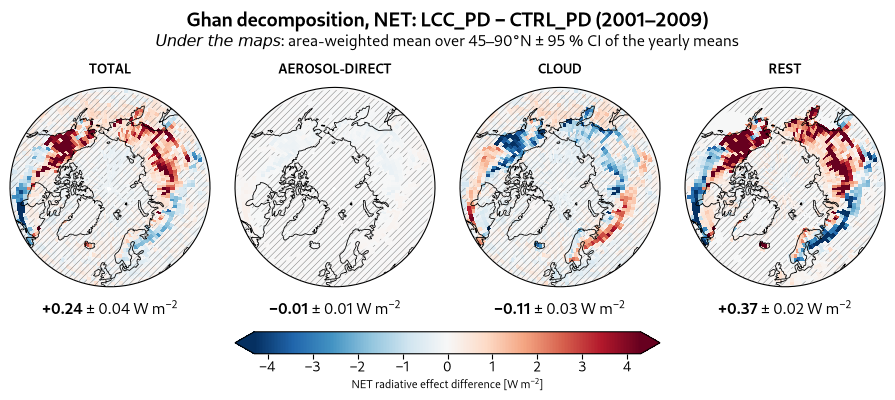

In [2]:
draw("ghan", "A_compact")

### Ghan decomposition: B current

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2
ghan, B_current: 11.4 × 4.9 in


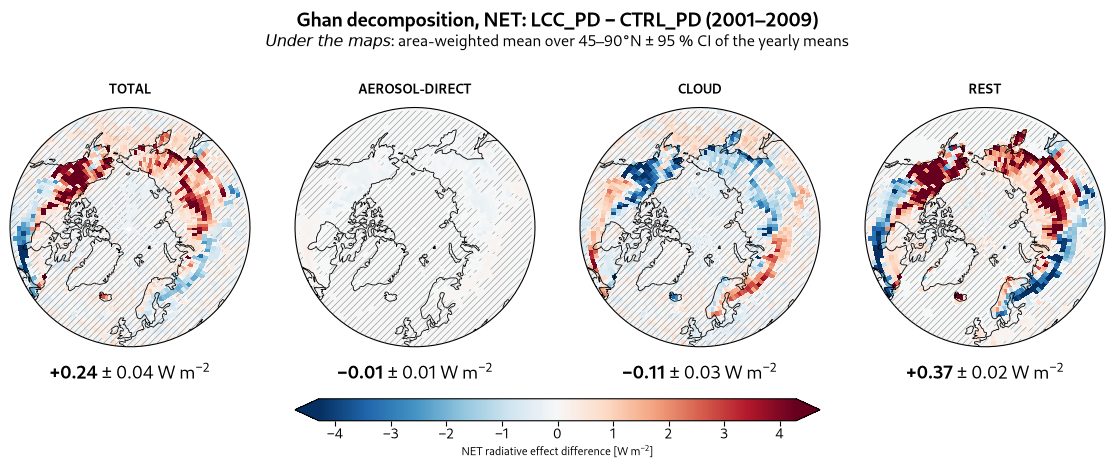

In [3]:
draw("ghan", "B_current")

### Ghan decomposition: C airy

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2
ghan, C_airy: 13.3 × 5.7 in


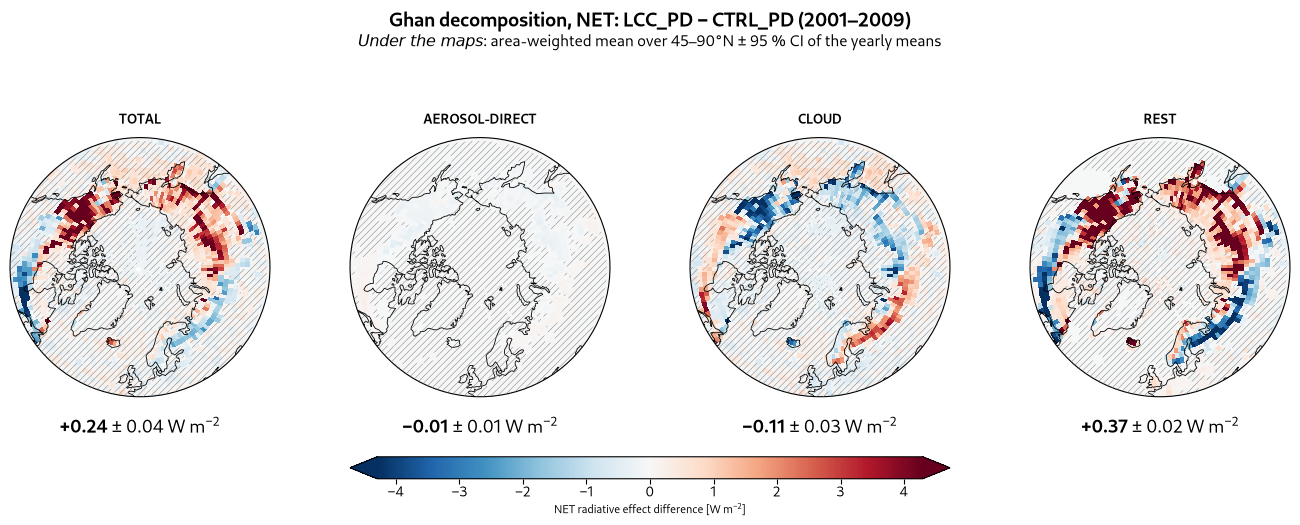

In [4]:
draw("ghan", "C_airy")

## Six-panel forcing summary (colourbar per panel)

### Six-panel forcing summary: A compact

summary, A_compact: 13.8 × 4.2 in


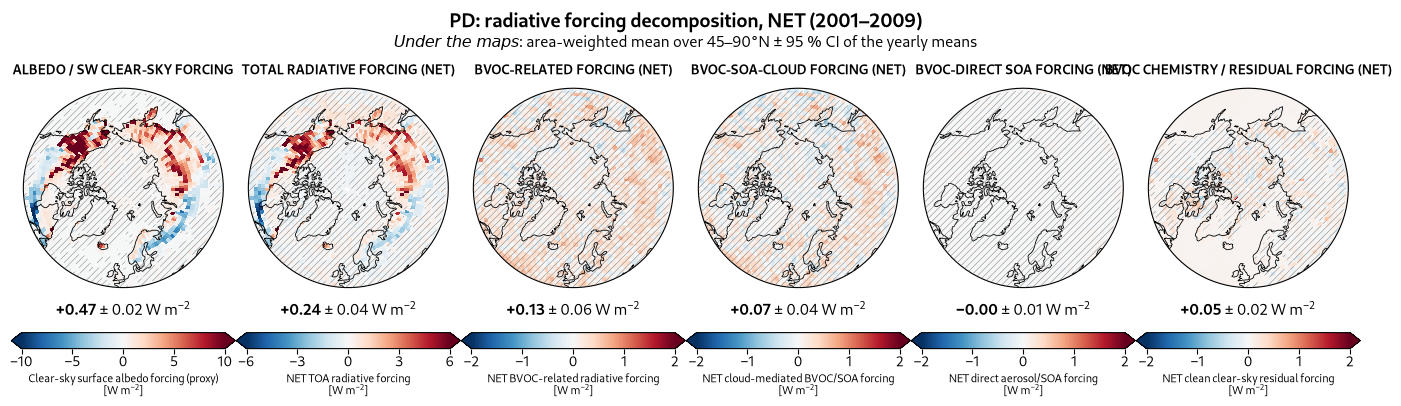

In [5]:
draw("summary", "A_compact")

### Six-panel forcing summary: B current

summary, B_current: 17.1 × 4.9 in


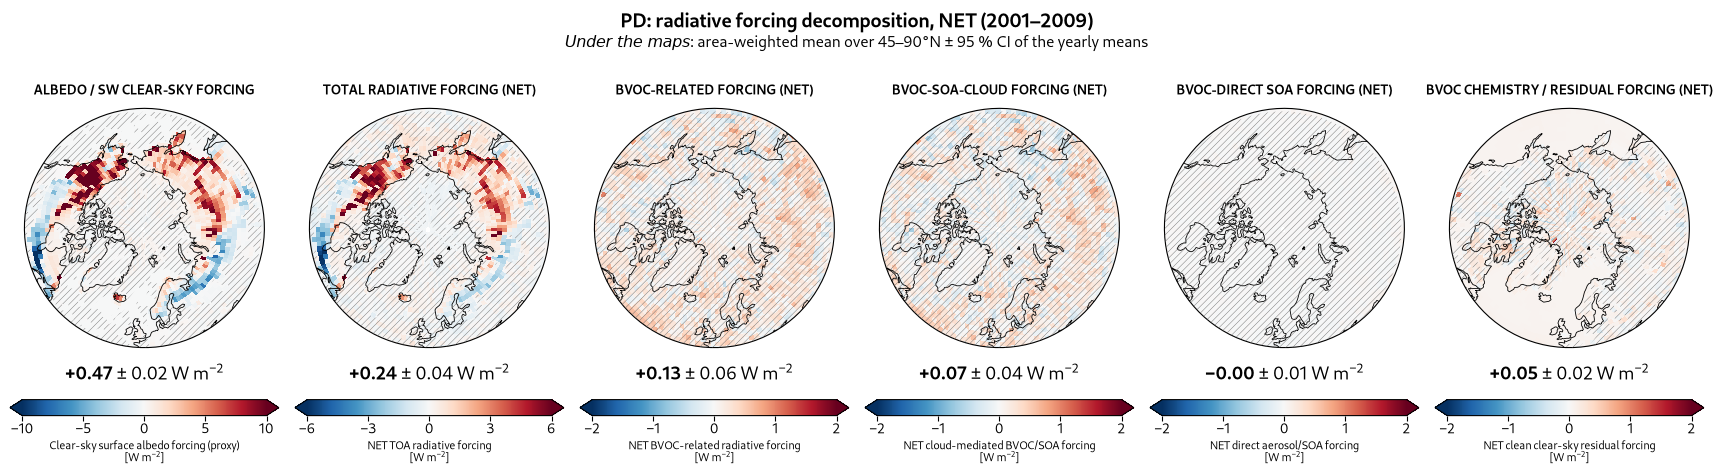

In [6]:
draw("summary", "B_current")

### Six-panel forcing summary: C airy

summary, C_airy: 20.1 × 5.7 in


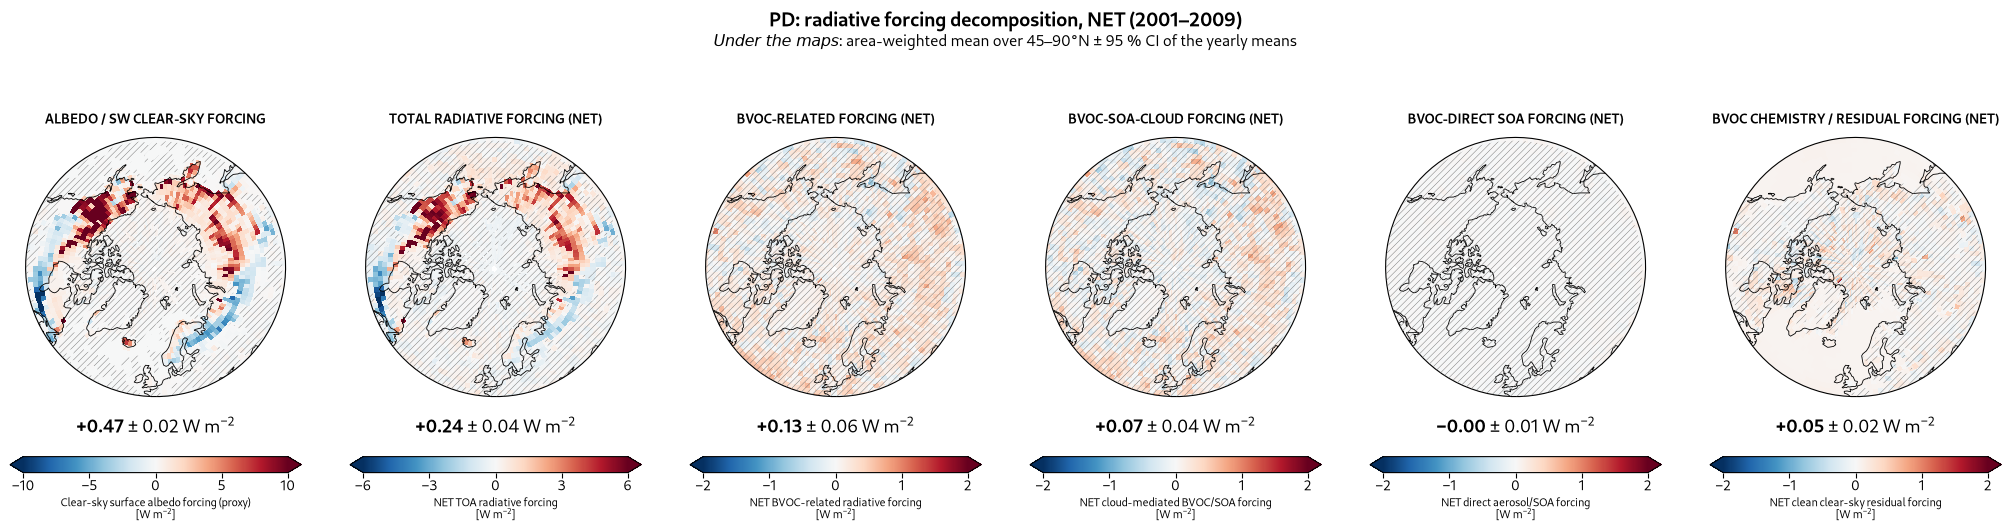

In [7]:
draw("summary", "C_airy")

## Contrast grid, FSDS split (2 rows)

### Contrast grid, FSDS split: A compact

grid, A_compact: 12.8 × 7.5 in


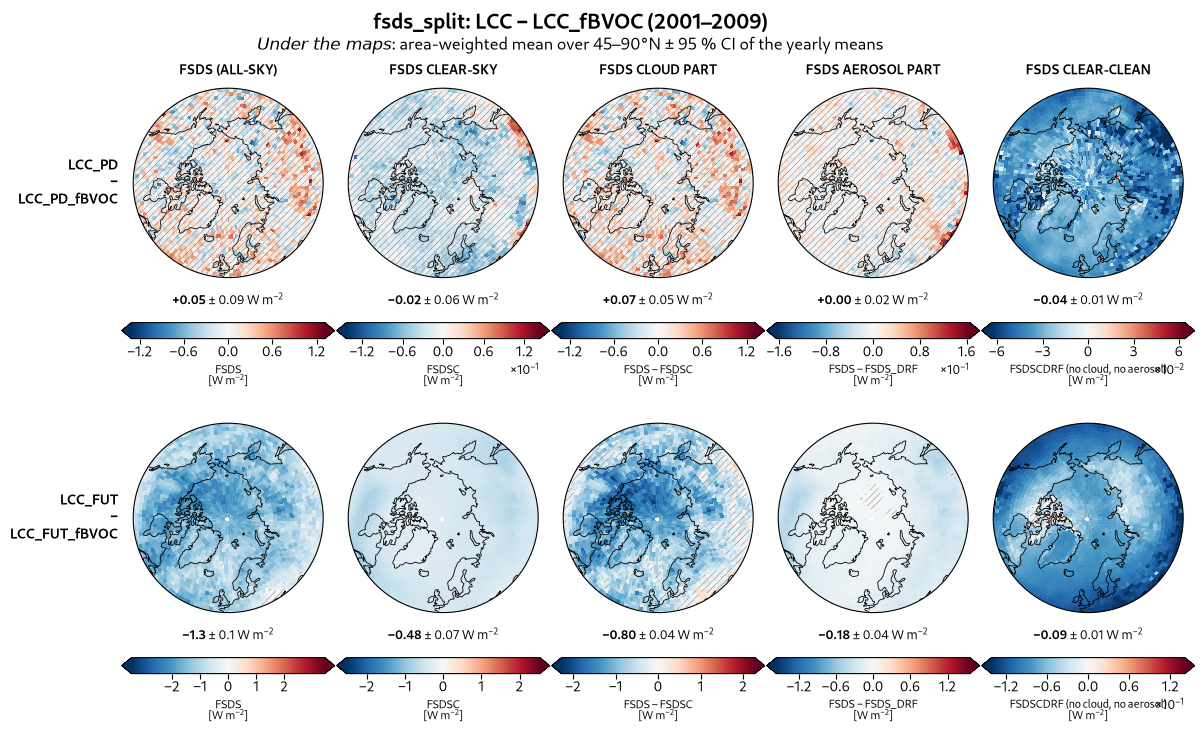

In [8]:
draw("grid", "A_compact")

### Contrast grid, FSDS split: B current

grid, B_current: 15.1 × 8.7 in


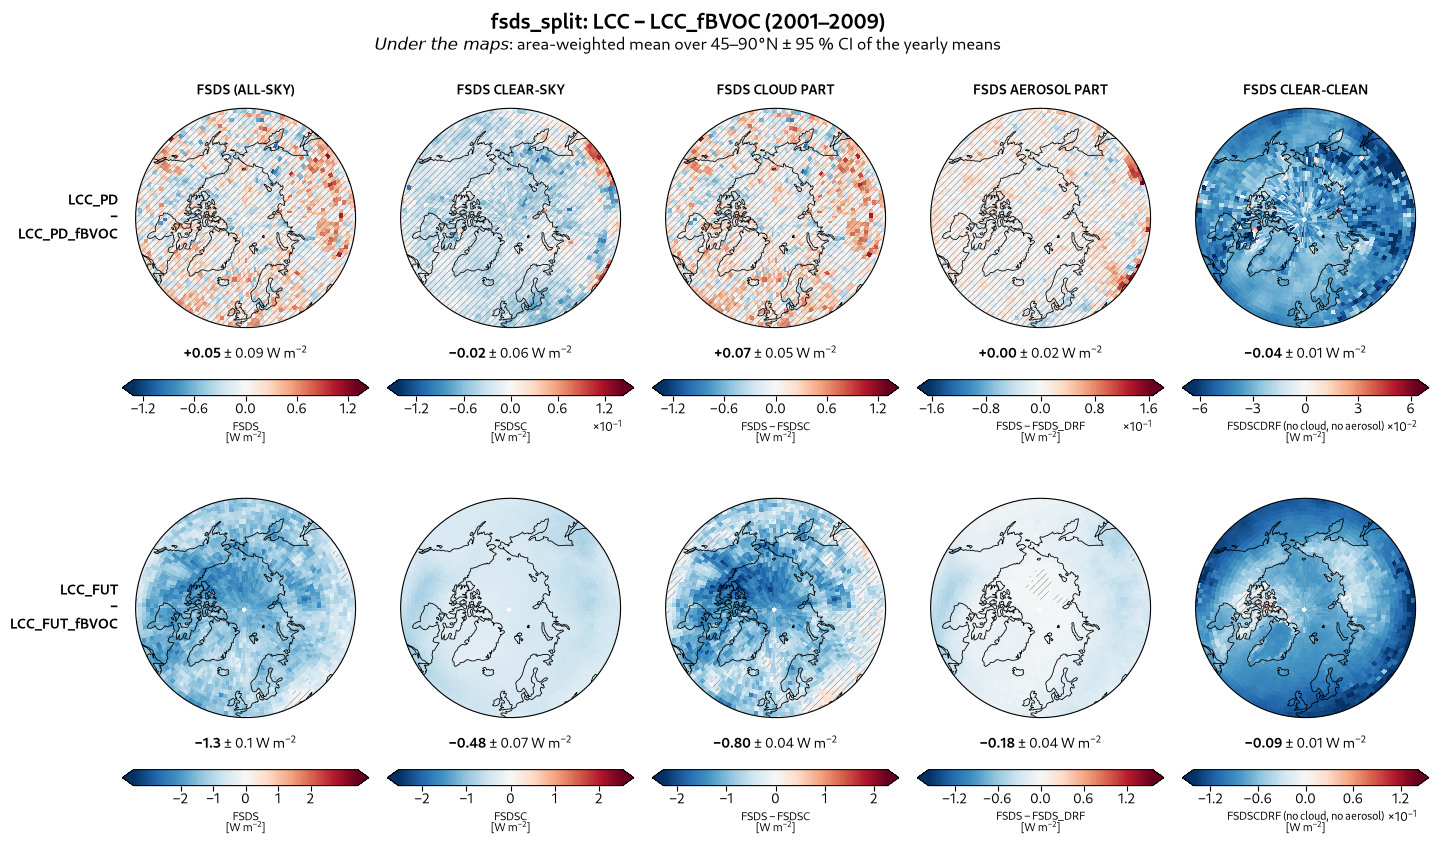

In [9]:
draw("grid", "B_current")

### Contrast grid, FSDS split: C airy

grid, C_airy: 17.4 × 10.0 in


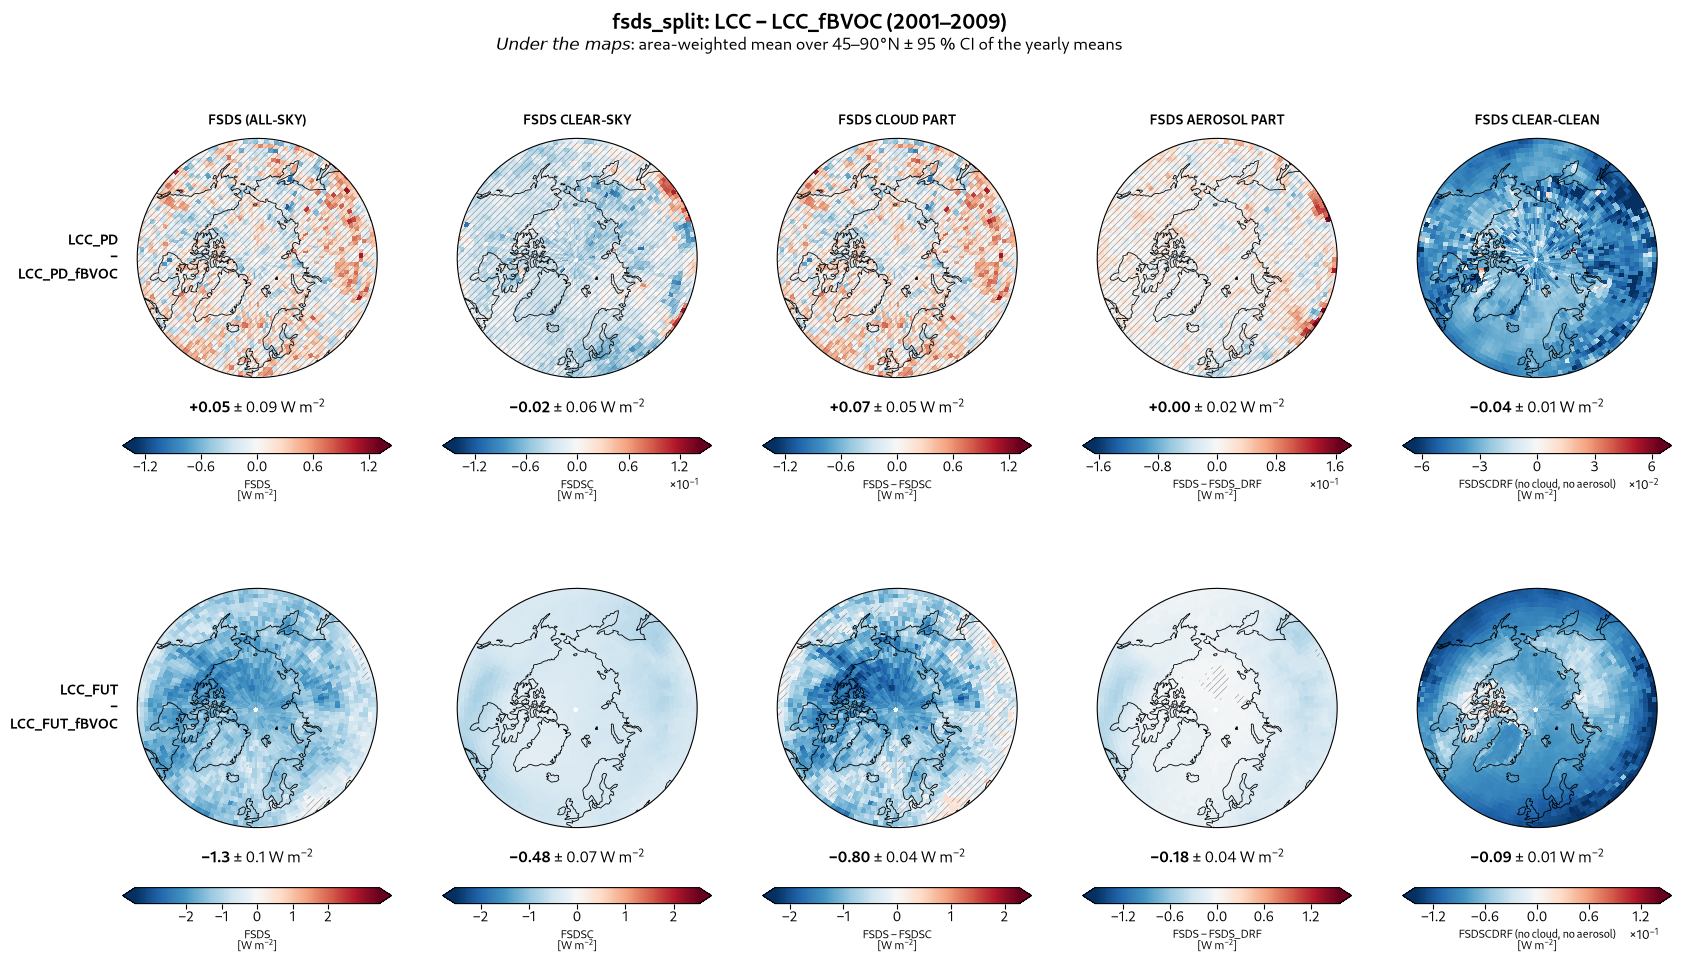

In [10]:
draw("grid", "C_airy")